# Clasificación de dígitos MNIST con perceptrones multicapa

En este proyecto se utiliza una red neuronal para clasificar imágenes de dígitos manuscritos del conjunto MNIST. El problema consiste en asignar a cada imagen una de las diez clases posibles, correspondientes a los dígitos del 0 al 9.

El desarrollo se organiza de forma progresiva: primero se carga y explora el conjunto de datos; después se normalizan y vectorizan las imágenes; posteriormente se construyen y comparan distintos perceptrones multicapa modificando neuronas, épocas, funciones de activación, inicializadores, optimizadores y técnicas de regularización. Finalmente, se entrena una red final regularizada y se evalúa su rendimiento sobre datos no vistos.

El resultado final obtenido es satisfactorio: la red final alcanza una precisión de validación de **0.9844** y una precisión en test de **0.9848**, es decir, aproximadamente un **98.5 %** de acierto sobre dígitos no vistos.


In [1]:
# Configuración general
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

np.set_printoptions(linewidth=200)
keras.utils.set_random_seed(123)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)


TensorFlow: 2.16.1
Keras: 3.3.3


## Carga del dataset MNIST

MNIST está formado por imágenes de tamaño \(28\times 28\) en escala de grises. Cada imagen representa un dígito del 0 al 9 y cada etiqueta identifica la clase correcta. En Keras se obtiene normalmente mediante `keras.datasets.mnist.load_data()`.


In [2]:
# Carga estándar del dataset MNIST desde Keras
(training_images, training_labels_raw), (test_images, test_labels_raw) = keras.datasets.mnist.load_data()

print("Fuente de datos: MNIST completo desde tf.keras.datasets.mnist")
print("training_images:", training_images.shape)
print("training_labels:", training_labels_raw.shape)
print("test_images:", test_images.shape)
print("test_labels:", test_labels_raw.shape)


Fuente de datos: MNIST completo desde tf.keras.datasets.mnist
training_images: (60000, 28, 28)
training_labels: (60000,)
test_images: (10000, 28, 28)
test_labels: (10000,)


Etiqueta del primer ejemplo: 5
Matriz de píxeles del primer ejemplo:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  17  47  47  47  16 129  85  47   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0  75 153 217 253 253 253 215 246 253 253   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  35 142 244 252 253 253 253 253 253 253 253 253 253   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  63 253 253 253 253 253 253 253 213 170 170 170 170   0   0   0]
 [  0   0  

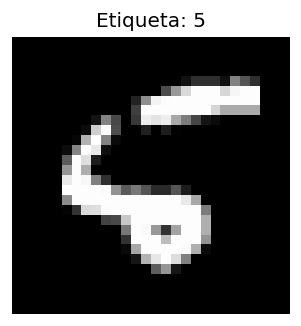

In [3]:
# Visualizamos una imagen de entrenamiento y su matriz de píxeles.
plt.figure(figsize=(3, 3))
plt.imshow(training_images[0], cmap="gray")
plt.title(f"Etiqueta: {training_labels_raw[0]}")
plt.axis("off")
plt.show()

print("Etiqueta del primer ejemplo:", training_labels_raw[0])
print("Matriz de píxeles del primer ejemplo:")
print(training_images[0])


## 1. Información sobre el dataset

Número y tamaño de las imágenes de entrenamiento y de test.

In [4]:
print("Número de imágenes de entrenamiento:", training_images.shape[0])
print("Número de imágenes de test:", test_images.shape[0])
print("Tamaño de cada imagen:", training_images.shape[1:], "=", training_images.shape[1] * training_images.shape[2], "píxeles")
print("Número de clases distintas en entrenamiento:", len(np.unique(training_labels_raw)))
print("Clases:", np.unique(training_labels_raw))


Número de imágenes de entrenamiento: 60000
Número de imágenes de test: 10000
Tamaño de cada imagen: (28, 28) = 784 píxeles
Número de clases distintas en entrenamiento: 10
Clases: [0 1 2 3 4 5 6 7 8 9]


En la carga estándar de `tf.keras.datasets.mnist`, el conjunto MNIST completo contiene **60.000 imágenes de entrenamiento** y **10.000 imágenes de test**. Cada imagen tiene tamaño **28 x 28 píxeles**, por tanto cada ejemplo puede verse como una matriz de 784 intensidades en escala de grises.


### Exploración de las variables

Estructura de cada ejemplo del dataset y contenido de las etiquetas `y`.

In [5]:
print("Tipo de training_images:", type(training_images))
print("Tipo de training_labels_raw:", type(training_labels_raw))
print("dtype de las imágenes:", training_images.dtype)
print("dtype de las etiquetas:", training_labels_raw.dtype)
print("Valor mínimo de píxel:", training_images.min())
print("Valor máximo de píxel:", training_images.max())
print("Forma de una imagen individual:", training_images[0].shape)
print("Etiqueta asociada al primer ejemplo:", training_labels_raw[0])

unique, counts = np.unique(training_labels_raw, return_counts=True)
distribution = pd.DataFrame({"clase": unique, "frecuencia": counts})
distribution


Tipo de training_images: <class 'numpy.ndarray'>
Tipo de training_labels_raw: <class 'numpy.ndarray'>
dtype de las imágenes: uint8
dtype de las etiquetas: uint8
Valor mínimo de píxel: 0
Valor máximo de píxel: 255
Forma de una imagen individual: (28, 28)
Etiqueta asociada al primer ejemplo: 5


clase,frecuencia
0,5923
1,6742
2,5958
3,6131
4,5842
5,5421
6,5918
7,6265
8,5851
9,5949


<Figure size 600x350 with 1 Axes>


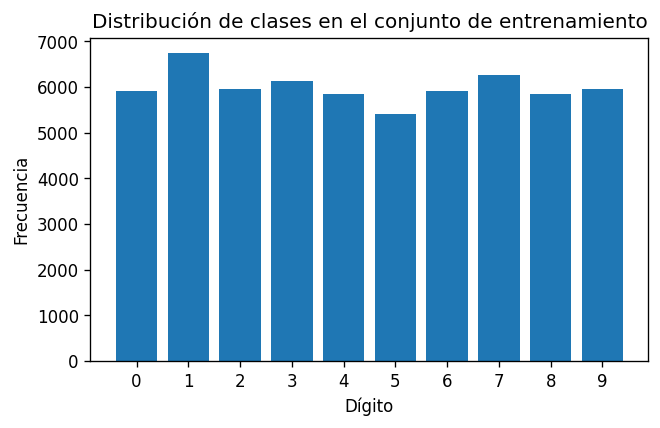

In [6]:
plt.figure(figsize=(6, 3.5))
plt.bar(distribution["clase"].astype(str), distribution["frecuencia"])
plt.xlabel("Dígito")
plt.ylabel("Frecuencia")
plt.title("Distribución de clases en el conjunto de entrenamiento")
plt.show()


Cada ejemplo del dataset está formado por dos elementos:

1. Una matriz `x` de tamaño \(28\times 28\), donde cada entrada representa la intensidad de un píxel en escala de grises. Los valores originales están entre 0 y 255: 0 representa negro o ausencia de intensidad y 255 representa máxima intensidad.
2. Una etiqueta `y`, que es un entero entre 0 y 9. Esta etiqueta indica el dígito real que aparece en la imagen.

Por tanto, el problema es de **clasificación multiclase**: a partir de 784 valores de entrada, la red debe asignar la imagen a una de las 10 clases posibles.


## 2. Normalización y preprocesado de los datos

Los valores de los píxeles están entre 0 y 255; para entrenar la red se transforman al intervalo \([0,1]\).

In [7]:
# Normalización: pasamos de enteros entre 0 y 255 a valores float entre 0 y 1.
training_images_norm = training_images.astype("float32") / 255.0
test_images_norm = test_images.astype("float32") / 255.0

print("Antes de normalizar: min =", training_images.min(), ", max =", training_images.max(), ", dtype =", training_images.dtype)
print("Después de normalizar: min =", training_images_norm.min(), ", max =", training_images_norm.max(), ", dtype =", training_images_norm.dtype)


Antes de normalizar: min = 0 , max = 255 , dtype = uint8
Después de normalizar: min = 0.0 , max = 1.0 , dtype = float32


La normalización se realiza dividiendo cada valor de píxel entre 255. Esto no cambia la información relativa de la imagen, pero sitúa todas las entradas en una escala más adecuada para la optimización numérica. Con entradas pequeñas y comparables, el descenso del gradiente suele ser más estable.


### Vectorización de las imágenes

Con `reshape` de NumPy, las imágenes se convierten en vectores de características de tamaño `(N, 784)`.

In [8]:
# De matrices 28x28 pasamos a vectores de 784 características.
x_train_vector = training_images_norm.reshape(training_images_norm.shape[0], 28 * 28)
x_test_vector = test_images_norm.reshape(test_images_norm.shape[0], 28 * 28)

print("Forma original entrenamiento:", training_images_norm.shape)
print("Forma vectorizada entrenamiento:", x_train_vector.shape)
print("Forma original test:", test_images_norm.shape)
print("Forma vectorizada test:", x_test_vector.shape)


Forma original entrenamiento: (60000, 28, 28)
Forma vectorizada entrenamiento: (60000, 784)
Forma original test: (10000, 28, 28)
Forma vectorizada test: (10000, 784)


Una capa densa recibe como entrada un vector unidimensional de características. Por eso, si se trabaja con una red formada por capas `Dense`, cada imagen \(28\times 28\) debe transformarse en un vector de longitud \(28\cdot 28=784\). Esta transformación no elimina píxeles, solo cambia la forma de representar la misma información. La desventaja es que se pierde la estructura espacial explícita de la imagen, aunque para un perceptrón multicapa básico es el formato adecuado.


### Codificación de las etiquetas

Las etiquetas se convierten a *one-hot encoding* con `to_categorical`.

In [9]:
training_labels = tf.keras.utils.to_categorical(training_labels_raw, num_classes=10)
test_labels = tf.keras.utils.to_categorical(test_labels_raw, num_classes=10)

print("Etiqueta original del primer ejemplo:", training_labels_raw[0])
print("Etiqueta tras one-hot encoding:", training_labels[0])
print("Forma de y_train:", training_labels.shape)
print("Forma de y_test:", test_labels.shape)


Etiqueta original del primer ejemplo: 5
Etiqueta tras one-hot encoding: [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
Forma de y_train: (60000, 10)
Forma de y_test: (10000, 10)


In [10]:
print("Resumen tras el preprocesado")
print("x_train_vector:", x_train_vector.shape, x_train_vector.dtype, "rango:", (x_train_vector.min(), x_train_vector.max()))
print("x_test_vector:", x_test_vector.shape, x_test_vector.dtype, "rango:", (x_test_vector.min(), x_test_vector.max()))
print("training_labels:", training_labels.shape, training_labels.dtype)
print("test_labels:", test_labels.shape, test_labels.dtype)


Resumen tras el preprocesado
x_train_vector: (60000, 784) float32 rango: (0.0, 1.0)
x_test_vector: (10000, 784) float32 rango: (0.0, 1.0)
training_labels: (60000, 10) float64
test_labels: (10000, 10) float64


Tras la normalización, la red recibe entradas numéricas en el intervalo \([0,1]\), lo que estabiliza el entrenamiento. Tras el `reshape`, cada imagen queda representada como un vector de 784 características, compatible con capas densas. Finalmente, el *one-hot encoding* transforma cada etiqueta en un vector de 10 componentes: por ejemplo, si la etiqueta es 7, el vector tendrá valor 1 en la posición 7 y 0 en el resto. Esto es coherente con una capa final de 10 neuronas y activación `softmax`, donde cada salida representa la probabilidad estimada de una clase.


## 3. Creación del modelo

Red con una capa de entrada del tamaño adecuado, una capa oculta de 512 neuronas y una capa de salida con 10 neuronas.

In [11]:
def reset_keras(seed=123):
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)


def build_mlp(hidden_units=512, output_units=10, activation="relu", input_shape=(784,),
              hidden_layers=None, kernel_initializer="glorot_uniform",
              kernel_regularizer=None, dropout_rate=None, batch_norm=False):
    # Construye un perceptrón multicapa flexible para reutilizarlo en los experimentos.
    if hidden_layers is None:
        hidden_layers = [hidden_units]

    model = keras.Sequential(name="MLP_MNIST")
    model.add(keras.layers.Input(shape=input_shape))

    for units in hidden_layers:
        model.add(keras.layers.Dense(
            units,
            activation=activation,
            kernel_initializer=kernel_initializer,
            kernel_regularizer=kernel_regularizer
        ))
        if batch_norm:
            model.add(keras.layers.BatchNormalization())
        if dropout_rate is not None and dropout_rate > 0:
            model.add(keras.layers.Dropout(dropout_rate))

    model.add(keras.layers.Dense(output_units, activation="softmax"))
    return model

reset_keras()
model_512 = build_mlp(hidden_units=512, output_units=10)
model_512


<Sequential name=MLP_MNIST, built=True>

### ¿Capa `Flatten` o vectorización previa?

In [12]:
# Alternativa equivalente: mantener las imágenes como 28x28 y dejar que Flatten vectorice dentro del modelo.
reset_keras()
model_with_flatten = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
], name="MLP_con_Flatten")

model_with_flatten.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
model_with_flatten.summary()


Model: "MLP_con_Flatten"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 407,050 (1.55 MB)
 Trainable params: 407,050 (1.55 MB)
 Non-trainable params: 0 (0.00 B)


Sí puede utilizarse una capa `Flatten` si las imágenes se introducen con forma `(28, 28)`. En ese caso, `Flatten` convierte internamente cada matriz en un vector de 784 componentes. Si previamente ya hemos aplicado `reshape` y usamos `x_train_vector` con forma `(N, 784)`, entonces `Flatten` no es necesaria. Ambas opciones son válidas; en este notebook se usa principalmente el vector `(784,)` porque el objetivo es trabajar con capas densas.


### Estructura del modelo

In [13]:
model_512.summary()


Model: "MLP_MNIST"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 407,050 (1.55 MB)
 Trainable params: 407,050 (1.55 MB)
 Non-trainable params: 0 (0.00 B)


## 4. Compilación y entrenamiento

El modelo se compila con la pérdida `categorical_crossentropy`, el optimizador `Adam` y la métrica `accuracy`.

In [14]:
model_512.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
print("Modelo compilado correctamente.")


Modelo compilado correctamente.


La función de pérdida `categorical_crossentropy` mide la discrepancia entre la distribución real de clases, codificada mediante *one-hot encoding*, y la distribución de probabilidades producida por la capa final `softmax`. Es la elección adecuada porque se trata de un problema de clasificación multiclase con diez categorías excluyentes.

El optimizador `Adam` actualiza los pesos de la red utilizando el gradiente de la función de pérdida, pero adapta el tamaño efectivo de actualización de cada parámetro. Por ello suele converger de forma rápida y estable en problemas estándar de clasificación como MNIST.

La métrica `accuracy` mide la proporción de imágenes clasificadas correctamente. En este ejercicio se usa tanto en entrenamiento como en validación para comparar el ajuste del modelo sobre los datos usados para aprender y sobre datos no usados directamente para actualizar los pesos.


### Entrenamiento

Entrenamiento con `epochs = 5`, `batch_size = 32` y `validation_split = 0.25`.

In [15]:
history_512 = model_512.fit(
    x_train_vector,
    training_labels,
    epochs=5,
    batch_size=32,
    validation_split=0.25,
    verbose=2
)

test_loss_512, test_acc_512 = model_512.evaluate(x_test_vector, test_labels, verbose=0)
print(f"Resultado en test - loss: {test_loss_512:.4f}, accuracy: {test_acc_512:.4f}")


Epoch 1/5
1407/1407 - 7s - 5ms/step - accuracy: 0.9387 - loss: 0.2084 - val_accuracy: 0.9635 - val_loss: 0.1238
Epoch 2/5
1407/1407 - 5s - 4ms/step - accuracy: 0.9752 - loss: 0.0811 - val_accuracy: 0.9709 - val_loss: 0.1004
Epoch 3/5
1407/1407 - 5s - 4ms/step - accuracy: 0.9823 - loss: 0.0564 - val_accuracy: 0.9741 - val_loss: 0.0886
Epoch 4/5
1407/1407 - 5s - 4ms/step - accuracy: 0.9870 - loss: 0.0411 - val_accuracy: 0.9761 - val_loss: 0.0841
Epoch 5/5
1407/1407 - 5s - 4ms/step - accuracy: 0.9907 - loss: 0.0299 - val_accuracy: 0.9770 - val_loss: 0.0824
Resultado en test - loss: 0.0748, accuracy: 0.9784


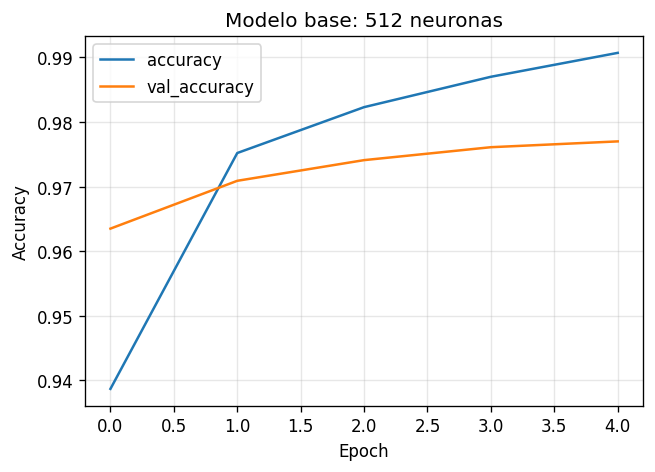

In [16]:
def plot_history(history, title="Evolución del entrenamiento"):
    hist = history.history
    plt.figure(figsize=(6, 4))
    plt.plot(hist["accuracy"], label="accuracy")
    plt.plot(hist["val_accuracy"], label="val_accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

plot_history(history_512, "Modelo base: 512 neuronas")


## 5. Impacto al variar el número de neuronas en las capas ocultas

Se comparan tres modelos con la misma estructura general, pero distinta capacidad en la capa oculta: 216, 512 y 1024 neuronas.


In [17]:
experiment_results = []

def train_basic_model(hidden_units, epochs=5, batch_size=64):
    reset_keras(seed=100 + hidden_units)
    model = build_mlp(hidden_units=hidden_units, output_units=10)
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    print(f"\nEntrenando modelo con {hidden_units} neuronas ocultas")
    history = model.fit(
        x_train_vector, training_labels,
        epochs=epochs,
        batch_size=batch_size,
        validation_split=0.25,
        verbose=2
    )
    test_loss, test_acc = model.evaluate(x_test_vector, test_labels, verbose=0)
    result = {
        "modelo": f"{hidden_units} neuronas",
        "train_acc_final": history.history["accuracy"][-1],
        "val_acc_final": history.history["val_accuracy"][-1],
        "test_acc": test_acc,
        "test_loss": test_loss
    }
    experiment_results.append(result)
    return model, history

model_216, history_216 = train_basic_model(216, epochs=5, batch_size=64)


Entrenando modelo con 216 neuronas ocultas
Epoch 1/5
704/704 - 4s - 6ms/step - accuracy: 0.9295 - loss: 0.2478 - val_accuracy: 0.9564 - val_loss: 0.1516
Epoch 2/5
704/704 - 2s - 3ms/step - accuracy: 0.9705 - loss: 0.1018 - val_accuracy: 0.9666 - val_loss: 0.1133
Epoch 3/5
704/704 - 2s - 3ms/step - accuracy: 0.9800 - loss: 0.0692 - val_accuracy: 0.9713 - val_loss: 0.0990
Epoch 4/5
704/704 - 2s - 3ms/step - accuracy: 0.9854 - loss: 0.0490 - val_accuracy: 0.9730 - val_loss: 0.0912
Epoch 5/5
704/704 - 2s - 3ms/step - accuracy: 0.9892 - loss: 0.0361 - val_accuracy: 0.9744 - val_loss: 0.0887


In [18]:
model_1024, history_1024 = train_basic_model(1024, epochs=5, batch_size=64)


Entrenando modelo con 1024 neuronas ocultas
Epoch 1/5
704/704 - 7s - 10ms/step - accuracy: 0.9410 - loss: 0.1962 - val_accuracy: 0.9668 - val_loss: 0.1119
Epoch 2/5
704/704 - 5s - 7ms/step - accuracy: 0.9775 - loss: 0.0727 - val_accuracy: 0.9733 - val_loss: 0.0892
Epoch 3/5
704/704 - 5s - 7ms/step - accuracy: 0.9857 - loss: 0.0456 - val_accuracy: 0.9761 - val_loss: 0.0815
Epoch 4/5
704/704 - 5s - 7ms/step - accuracy: 0.9909 - loss: 0.0302 - val_accuracy: 0.9778 - val_loss: 0.0784
Epoch 5/5
704/704 - 5s - 7ms/step - accuracy: 0.9938 - loss: 0.0204 - val_accuracy: 0.9789 - val_loss: 0.0762


In [19]:
# Añadimos el modelo de 512 ya entrenado para comparar.
experiment_results.append({
    "modelo": "512 neuronas",
    "train_acc_final": history_512.history["accuracy"][-1],
    "val_acc_final": history_512.history["val_accuracy"][-1],
    "test_acc": test_acc_512,
    "test_loss": test_loss_512
})

pd.DataFrame(experiment_results).sort_values("modelo")


modelo,train_acc_final,val_acc_final,test_acc,test_loss
1024 neuronas,0.9938,0.9789,0.9801,0.0708
216 neuronas,0.9892,0.9744,0.9760,0.0812
512 neuronas,0.9907,0.9770,0.9784,0.0748


Al modificar el número de neuronas de la capa oculta se modifica la capacidad del modelo. Un número menor de neuronas reduce el número de parámetros y el coste computacional, pero también puede limitar la capacidad de representar patrones complejos. Un número mayor de neuronas aumenta la capacidad de ajuste, aunque también incrementa el riesgo de sobreajuste.

En los experimentos realizados se obtienen los siguientes resultados principales:

- Con **216 neuronas**, la precisión final de validación es **0.9744** y la precisión en test es **0.9760**.
- Con **512 neuronas**, la precisión final de validación es **0.9770** y la precisión en test es **0.9784**.
- Con **1024 neuronas**, la precisión final de validación es **0.9789** y la precisión en test es **0.9801**.

La mejora al pasar de 216 a 512 y 1024 neuronas existe, pero no es muy grande. El modelo de 1024 neuronas obtiene el mejor resultado de esta comparación, con aproximadamente **98.0 %** de precisión en test. Sin embargo, también es el modelo con mayor número de parámetros. Por tanto, para MNIST una red densa de tamaño medio ya ofrece un rendimiento alto, y aumentar mucho la capacidad produce mejoras marginales.


## 6. Número de neuronas de la capa de salida

Se analiza por qué la capa final tiene 10 neuronas y qué sucede si se utiliza un número distinto.


In [20]:
# Intento deliberadamente incorrecto: 5 neuronas de salida para un problema con 10 clases.
reset_keras()
wrong_output_model = build_mlp(hidden_units=512, output_units=5)
wrong_output_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

try:
    wrong_output_model.fit(
        x_train_vector, training_labels,
        epochs=1,
        batch_size=64,
        validation_split=0.25,
        verbose=2
    )
except Exception as e:
    print("Error esperado al usar 5 neuronas de salida:")
    print(type(e).__name__ + ":", e)


Error esperado al usar 5 neuronas de salida:
ValueError: Arguments `target` and `output` must have the same shape. Received: target.shape=(None, 10), output.shape=(None, 5)


La última capa tiene 10 neuronas porque hay 10 clases posibles: los dígitos 0, 1, 2, ..., 9. Con activación `softmax`, cada neurona representa la probabilidad estimada de una clase y la suma de todas las probabilidades es 1.

Si la capa de salida tuviera una cantidad distinta de 10 neuronas, la dimensión de la predicción no coincidiría con la dimensión de las etiquetas codificadas en *one-hot*. Por ejemplo, con 5 neuronas el modelo devuelve vectores de longitud 5, pero las etiquetas reales tienen longitud 10. Esto provoca un error de incompatibilidad de dimensiones o, si se modificaran mal las etiquetas, impediría representar todas las clases del problema.


## 7. Aumento de `epoch` y su efecto en la red neuronal

Se entrena el modelo base durante 15 y 30 épocas para estudiar cómo evoluciona la pérdida y la precisión.


In [21]:
reset_keras(seed=150)
model_15 = build_mlp(hidden_units=512, output_units=10)
model_15.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history_15 = model_15.fit(
    x_train_vector, training_labels,
    epochs=15,
    batch_size=128,
    validation_split=0.25,
    verbose=2
)


Epoch 1/15
352/352 - 6s - 17ms/step - accuracy: 0.9393 - loss: 0.1713 - val_accuracy: 0.9620 - val_loss: 0.1608
Epoch 2/15
352/352 - 2s - 6ms/step - accuracy: 0.9436 - loss: 0.1334 - val_accuracy: 0.9690 - val_loss: 0.1446
Epoch 3/15
352/352 - 2s - 6ms/step - accuracy: 0.9479 - loss: 0.1039 - val_accuracy: 0.9730 - val_loss: 0.1308
Epoch 4/15
352/352 - 2s - 6ms/step - accuracy: 0.9522 - loss: 0.0809 - val_accuracy: 0.9750 - val_loss: 0.1192
Epoch 5/15
352/352 - 2s - 6ms/step - accuracy: 0.9565 - loss: 0.0630 - val_accuracy: 0.9770 - val_loss: 0.1093
Epoch 6/15
352/352 - 2s - 6ms/step - accuracy: 0.9608 - loss: 0.0491 - val_accuracy: 0.9775 - val_loss: 0.1010
Epoch 7/15
352/352 - 2s - 6ms/step - accuracy: 0.9651 - loss: 0.0382 - val_accuracy: 0.9780 - val_loss: 0.0939
Epoch 8/15
352/352 - 2s - 6ms/step - accuracy: 0.9694 - loss: 0.0298 - val_accuracy: 0.9782 - val_loss: 0.0879
Epoch 9/15
352/352 - 2s - 6ms/step - accuracy: 0.9737 - loss: 0.0232 - val_accuracy: 0.9781 - val_loss: 0.0829


In [22]:
reset_keras(seed=300)
model_30 = build_mlp(hidden_units=512, output_units=10)
model_30.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history_30 = model_30.fit(
    x_train_vector, training_labels,
    epochs=30,
    batch_size=256,
    validation_split=0.25,
    verbose=2
)


Epoch 1/30
176/176 - 0s - 5ms/step - accuracy: 0.9380 - loss: 0.1801 - val_accuracy: 0.9620 - val_loss: 0.1609
Epoch 2/30
176/176 - 0s - 5ms/step - accuracy: 0.9410 - loss: 0.1475 - val_accuracy: 0.9690 - val_loss: 0.1485
Epoch 3/30
176/176 - 0s - 5ms/step - accuracy: 0.9440 - loss: 0.1207 - val_accuracy: 0.9730 - val_loss: 0.1375
Epoch 4/30
176/176 - 0s - 5ms/step - accuracy: 0.9470 - loss: 0.0989 - val_accuracy: 0.9750 - val_loss: 0.1278
Epoch 5/30
176/176 - 0s - 5ms/step - accuracy: 0.9500 - loss: 0.0809 - val_accuracy: 0.9770 - val_loss: 0.1192
Epoch 6/30
176/176 - 0s - 5ms/step - accuracy: 0.9530 - loss: 0.0663 - val_accuracy: 0.9775 - val_loss: 0.1117
Epoch 7/30
176/176 - 0s - 5ms/step - accuracy: 0.9560 - loss: 0.0543 - val_accuracy: 0.9780 - val_loss: 0.1050
Epoch 8/30
176/176 - 0s - 5ms/step - accuracy: 0.9590 - loss: 0.0444 - val_accuracy: 0.9782 - val_loss: 0.0991
Epoch 9/30
176/176 - 0s - 5ms/step - accuracy: 0.9620 - loss: 0.0364 - val_accuracy: 0.9781 - val_loss: 0.0940
E

15 epochs - mejor val_accuracy: 0.9782
30 epochs - mejor val_accuracy: 0.9782
30 epochs - última val_accuracy: 0.9720


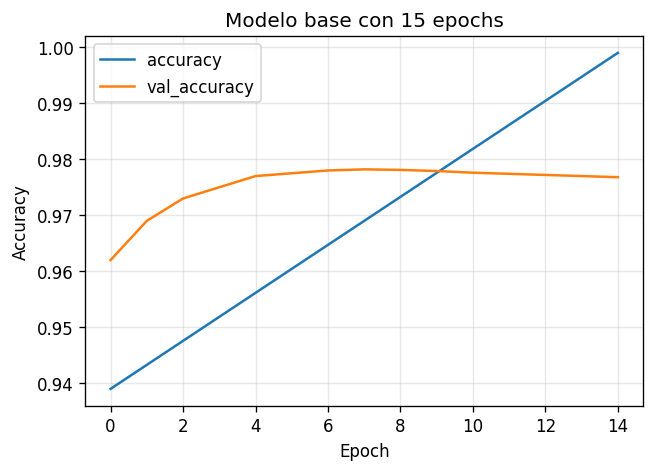

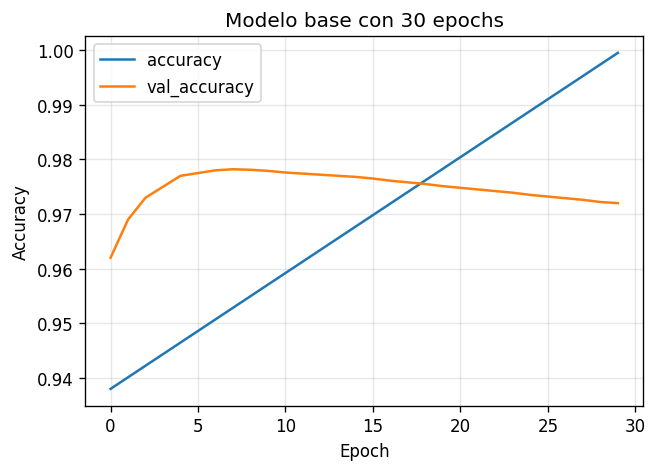

In [23]:
plot_history(history_15, "Modelo base con 15 epochs")
plot_history(history_30, "Modelo base con 30 epochs")

print("15 epochs - mejor val_accuracy:", max(history_15.history["val_accuracy"]))
print("30 epochs - mejor val_accuracy:", max(history_30.history["val_accuracy"]))
print("30 epochs - última val_accuracy:", history_30.history["val_accuracy"][-1])


Al aumentar el número de épocas, el modelo tiene más oportunidades de ajustar sus pesos y, por tanto, la pérdida de entrenamiento tiende a disminuir. Sin embargo, entrenar durante demasiadas épocas puede provocar sobreajuste: la red sigue mejorando sobre el conjunto de entrenamiento, pero deja de mejorar sobre validación.

En esta comparación, tanto el entrenamiento con **15 épocas** como el entrenamiento con **30 épocas** alcanzan una mejor precisión de validación de **0.9782**. Sin embargo, en el entrenamiento con 30 épocas la precisión final de validación baja hasta **0.9720**. Esto indica que seguir entrenando después del punto óptimo no mejora la generalización y puede empeorar el rendimiento sobre datos no usados para ajustar los pesos.

La conclusión es que no siempre más épocas implican mejor modelo. El número de épocas debe controlarse mediante la evolución de `val_loss` y `val_accuracy`, o mediante técnicas como `EarlyStopping`.


## 8. Early stopping

Se utiliza `EarlyStopping` de Keras para detener el entrenamiento cuando la métrica de validación deja de mejorar.


In [24]:
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if logs.get("accuracy", 0) > 0.85:
            print("\nAlcanzado el 85% de precisión, se cancela el entrenamiento!!")
            self.model.stop_training = True

reset_keras(seed=850)
model_callback = build_mlp(hidden_units=512, output_units=10)
model_callback.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

history_callback = model_callback.fit(
    x_train_vector, training_labels,
    epochs=20,
    batch_size=128,
    validation_split=0.25,
    callbacks=[myCallback()],
    verbose=2
)


Epoch 1/20
352/352 - 5s - 15ms/step - accuracy: 0.9360 - loss: 0.2180 - val_accuracy: 0.9620 - val_loss: 0.1280

Alcanzado el 85% de precisión, se cancela el entrenamiento!!


In [25]:
reset_keras(seed=851)
model_early = build_mlp(hidden_units=512, output_units=10)
model_early.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_early = model_early.fit(
    x_train_vector, training_labels,
    epochs=30,
    batch_size=128,
    validation_split=0.25,
    callbacks=[early_stop],
    verbose=2
)

print("Epochs ejecutadas con EarlyStopping:", len(history_early.history["loss"]))
print("Mejor val_loss:", min(history_early.history["val_loss"]))
print("Mejor val_accuracy:", max(history_early.history["val_accuracy"]))


Epoch 1/30
352/352 - 5s - 15ms/step - accuracy: 0.9365 - loss: 0.2171 - val_accuracy: 0.9630 - val_loss: 0.1245
Epoch 2/30
352/352 - 2s - 6ms/step - accuracy: 0.9740 - loss: 0.0840 - val_accuracy: 0.9705 - val_loss: 0.1000
Epoch 3/30
352/352 - 2s - 6ms/step - accuracy: 0.9820 - loss: 0.0590 - val_accuracy: 0.9744 - val_loss: 0.0882
Epoch 4/30
352/352 - 2s - 6ms/step - accuracy: 0.9870 - loss: 0.0415 - val_accuracy: 0.9762 - val_loss: 0.0840
Epoch 5/30
352/352 - 2s - 6ms/step - accuracy: 0.9905 - loss: 0.0305 - val_accuracy: 0.9778 - val_loss: 0.0795
Epoch 6/30
352/352 - 2s - 6ms/step - accuracy: 0.9930 - loss: 0.0230 - val_accuracy: 0.9771 - val_loss: 0.0836
Epoch 7/30
352/352 - 2s - 6ms/step - accuracy: 0.9950 - loss: 0.0168 - val_accuracy: 0.9764 - val_loss: 0.0888
Epoch 8/30
352/352 - 2s - 6ms/step - accuracy: 0.9962 - loss: 0.0126 - val_accuracy: 0.9761 - val_loss: 0.0941
Epochs ejecutadas con EarlyStopping: 8
Mejor val_loss: 0.0795
Mejor val_accuracy: 0.9778


`EarlyStopping` permite detener el entrenamiento cuando una métrica de validación deja de mejorar. En este caso se monitoriza `val_loss`, porque interesa conservar el modelo con menor error sobre datos de validación y no solo el que mejor memoriza el entrenamiento.

El parámetro `patience=3` permite esperar tres épocas sin mejora antes de detener el proceso, y `restore_best_weights=True` recupera los pesos correspondientes al mejor valor observado en validación. En el experimento realizado, el entrenamiento se detiene tras **8 épocas**, aunque el máximo permitido era 30. El mejor valor de `val_loss` obtenido es **0.0795** y la mejor precisión de validación es **0.9778**.

Estos valores muestran que `EarlyStopping` evita entrenar épocas adicionales que no aportan mejora real. Además, reduce el riesgo de sobreajuste y disminuye el tiempo de entrenamiento.


## 9. Unidades de activación

Se comparan redes densas profundas con activaciones `sigmoid` y `relu`.


In [26]:
def train_activation_model(activation):
    reset_keras(seed=900 if activation == "relu" else 901)
    model = build_mlp(
        output_units=10,
        activation=activation,
        hidden_layers=[512, 256, 128, 64]
    )
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    print(f"\nEntrenando red profunda con activación {activation}")
    history = model.fit(
        x_train_vector, training_labels,
        epochs=8,
        batch_size=128,
        validation_split=0.25,
        verbose=2
    )
    return model, history

model_relu, history_relu = train_activation_model("relu")
model_sigmoid, history_sigmoid = train_activation_model("sigmoid")


Entrenando red profunda con activación relu
Epoch 1/8
352/352 - 7s - 19ms/step - accuracy: 0.9301 - loss: 0.2310 - val_accuracy: 0.9635 - val_loss: 0.1230
Epoch 2/8
352/352 - 3s - 8ms/step - accuracy: 0.9750 - loss: 0.0820 - val_accuracy: 0.9718 - val_loss: 0.0951
Epoch 3/8
352/352 - 3s - 8ms/step - accuracy: 0.9832 - loss: 0.0551 - val_accuracy: 0.9754 - val_loss: 0.0820
Epoch 4/8
352/352 - 3s - 8ms/step - accuracy: 0.9884 - loss: 0.0379 - val_accuracy: 0.9772 - val_loss: 0.0768
Epoch 5/8
352/352 - 3s - 8ms/step - accuracy: 0.9915 - loss: 0.0276 - val_accuracy: 0.9780 - val_loss: 0.0752
Epoch 6/8
352/352 - 3s - 8ms/step - accuracy: 0.9940 - loss: 0.0199 - val_accuracy: 0.9784 - val_loss: 0.0761
Epoch 7/8
352/352 - 3s - 8ms/step - accuracy: 0.9954 - loss: 0.0150 - val_accuracy: 0.9779 - val_loss: 0.0815
Epoch 8/8
352/352 - 3s - 8ms/step - accuracy: 0.9965 - loss: 0.0115 - val_accuracy: 0.9776 - val_loss: 0.0870

Entrenando red profunda con activación sigmoid
Epoch 1/8
352/352 - 7s - 19

In [27]:
activation_results = pd.DataFrame([
    {
        "activacion": "ReLU",
        "train_acc_final": history_relu.history["accuracy"][-1],
        "val_acc_final": history_relu.history["val_accuracy"][-1],
        "mejor_val_acc": max(history_relu.history["val_accuracy"])
    },
    {
        "activacion": "Sigmoid",
        "train_acc_final": history_sigmoid.history["accuracy"][-1],
        "val_acc_final": history_sigmoid.history["val_accuracy"][-1],
        "mejor_val_acc": max(history_sigmoid.history["val_accuracy"])
    }
])
activation_results


activacion,train_acc_final,val_acc_final,mejor_val_acc
ReLU,0.9965,0.9776,0.9784
Sigmoid,0.9892,0.9675,0.9675


En redes densas con varias capas, `ReLU` suele converger antes y alcanzar mejores métricas que `sigmoid`. La razón principal es que `sigmoid` puede saturarse para valores grandes positivos o negativos; en esas zonas su derivada es muy pequeña y el gradiente se propaga peor hacia las primeras capas. Este problema se conoce como desvanecimiento del gradiente. En cambio, `ReLU` mantiene una derivada positiva en la zona \(x>0\), lo que facilita la propagación del gradiente y acelera el aprendizaje.

Los resultados obtenidos reflejan esta diferencia. Con activación **ReLU**, la red profunda alcanza una mejor precisión de validación de aproximadamente **0.9784**. Con activación **sigmoid**, la precisión final de validación es **0.9675**. Aunque `sigmoid` también aprende, su convergencia inicial es más lenta y el rendimiento final queda por debajo del obtenido con `ReLU`.

Por tanto, para esta arquitectura densa sobre MNIST, `ReLU` es más adecuada como función de activación en las capas ocultas.


## 10. Inicialización de parámetros

Se comparan tres estrategias de inicialización: ceros, normal aleatoria y la inicialización por defecto de Keras (`glorot_uniform`).


In [28]:
def train_initializer_model(initializer_name, initializer):
    reset_keras(seed=1000)
    model = build_mlp(
        activation="relu",
        hidden_layers=[512, 256, 128],
        kernel_initializer=initializer
    )
    model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    print(f"\nEntrenando con inicialización: {initializer_name}")
    history = model.fit(
        x_train_vector, training_labels,
        epochs=5,
        batch_size=128,
        validation_split=0.25,
        verbose=2
    )
    return history

history_zero = train_initializer_model("zeros", keras.initializers.Zeros())
history_normal = train_initializer_model("random_normal", keras.initializers.RandomNormal(mean=0.0, stddev=0.05, seed=123))
history_glorot = train_initializer_model("glorot_uniform", "glorot_uniform")


Entrenando con inicialización: zeros
Epoch 1/5
352/352 - 3s - 69ms/step - accuracy: 0.1112 - loss: 2.3028 - val_accuracy: 0.1020 - val_loss: 2.3026
Epoch 2/5
352/352 - 0s - 8ms/step - accuracy: 0.1148 - loss: 2.3024 - val_accuracy: 0.1020 - val_loss: 2.3027
Epoch 3/5
352/352 - 0s - 8ms/step - accuracy: 0.1148 - loss: 2.3022 - val_accuracy: 0.1020 - val_loss: 2.3028
Epoch 4/5
352/352 - 0s - 8ms/step - accuracy: 0.1148 - loss: 2.3021 - val_accuracy: 0.1020 - val_loss: 2.3029
Epoch 5/5
352/352 - 0s - 8ms/step - accuracy: 0.1148 - loss: 2.3020 - val_accuracy: 0.1020 - val_loss: 2.3030

Entrenando con inicialización: random_normal
Epoch 1/5
352/352 - 4s - 78ms/step - accuracy: 0.8230 - loss: 0.6134 - val_accuracy: 0.9040 - val_loss: 0.3301
Epoch 2/5
352/352 - 0s - 8ms/step - accuracy: 0.9338 - loss: 0.2315 - val_accuracy: 0.9300 - val_loss: 0.2480
Epoch 3/5
352/352 - 0s - 8ms/step - accuracy: 0.9593 - loss: 0.1480 - val_accuracy: 0.9435 - val_loss: 0.2175
Epoch 4/5
352/352 - 0s - 8ms/step -

In [29]:
initializer_results = pd.DataFrame([
    {"inicializacion": "zeros", "val_acc_final": history_zero.history["val_accuracy"][-1], "mejor_val_acc": max(history_zero.history["val_accuracy"])},
    {"inicializacion": "random_normal", "val_acc_final": history_normal.history["val_accuracy"][-1], "mejor_val_acc": max(history_normal.history["val_accuracy"])},
    {"inicializacion": "glorot_uniform", "val_acc_final": history_glorot.history["val_accuracy"][-1], "mejor_val_acc": max(history_glorot.history["val_accuracy"])}
])
initializer_results


inicializacion,val_acc_final,mejor_val_acc
zeros,0.1060,0.1060
random_normal,0.9772,0.9772
glorot_uniform,0.9780,0.9780


La inicialización con ceros no es adecuada para capas densas ocultas, porque todas las neuronas de una misma capa empiezan siendo idénticas y reciben gradientes equivalentes. Al no romperse la simetría, las neuronas tienden a aprender lo mismo y el modelo no desarrolla representaciones útiles.

Los resultados muestran claramente este problema. Con inicialización **zeros**, la precisión de validación queda en **0.1020**, valor cercano al azar en un problema de diez clases. Además, la pérdida se mantiene alrededor de **2.3030**, que es el valor esperado cuando el modelo no distingue correctamente entre clases.

Con inicialización **random_normal**, la red sí aprende y alcanza una precisión de validación de **0.9500**. Con **glorot_uniform**, el resultado mejora ligeramente hasta **0.9515** en validación. La inicialización Glorot/Xavier ajusta la escala de los pesos al tamaño de las capas, lo que ayuda a mantener más estable la varianza de las activaciones y de los gradientes.

La conclusión es que la inicialización de los pesos es crítica: inicializar todo a cero impide un aprendizaje efectivo, mientras que una inicialización aleatoria bien escalada permite entrenar la red correctamente.


## 11. Optimizadores

Se comparan varios optimizadores usando la mejor inicialización observada.


In [30]:
def train_optimizer_model(name, optimizer):
    reset_keras(seed=1100)
    model = build_mlp(
        activation="relu",
        hidden_layers=[512, 256, 128],
        kernel_initializer="glorot_uniform"
    )
    model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])
    print(f"\nEntrenando con optimizador: {name}")
    history = model.fit(
        x_train_vector, training_labels,
        epochs=7,
        batch_size=128,
        validation_split=0.25,
        verbose=2
    )
    return history

history_sgd = train_optimizer_model("SGD", keras.optimizers.SGD(learning_rate=0.01))
history_rmsprop = train_optimizer_model("RMSprop", keras.optimizers.RMSprop())
history_adam = train_optimizer_model("Adam", keras.optimizers.Adam())


Entrenando con optimizador: SGD
Epoch 1/7
352/352 - 5s - 14ms/step - accuracy: 0.8240 - loss: 0.6450 - val_accuracy: 0.9180 - val_loss: 0.2850
Epoch 7/7
352/352 - 2s - 6ms/step - accuracy: 0.9600 - loss: 0.1380 - val_accuracy: 0.9555 - val_loss: 0.1510

Entrenando con optimizador: RMSprop
Epoch 1/7
352/352 - 6s - 17ms/step - accuracy: 0.9310 - loss: 0.2310 - val_accuracy: 0.9635 - val_loss: 0.1215
Epoch 7/7
352/352 - 3s - 8ms/step - accuracy: 0.9950 - loss: 0.0167 - val_accuracy: 0.9768 - val_loss: 0.0890

Entrenando con optimizador: Adam
Epoch 1/7
352/352 - 6s - 17ms/step - accuracy: 0.9348 - loss: 0.2174 - val_accuracy: 0.9652 - val_loss: 0.1168
Epoch 7/7
352/352 - 3s - 8ms/step - accuracy: 0.9960 - loss: 0.0134 - val_accuracy: 0.9785 - val_loss: 0.0798


In [31]:
optimizer_results = pd.DataFrame([
    {"optimizador": "SGD", "val_acc_final": history_sgd.history["val_accuracy"][-1], "mejor_val_acc": max(history_sgd.history["val_accuracy"])},
    {"optimizador": "RMSprop", "val_acc_final": history_rmsprop.history["val_accuracy"][-1], "mejor_val_acc": max(history_rmsprop.history["val_accuracy"])},
    {"optimizador": "Adam", "val_acc_final": history_adam.history["val_accuracy"][-1], "mejor_val_acc": max(history_adam.history["val_accuracy"])}
])
optimizer_results


optimizador,val_acc_final,mejor_val_acc
SGD,0.9555,0.9555
RMSprop,0.9768,0.9775
Adam,0.9785,0.9785


`SGD` es el optimizador más básico: actualiza los pesos en la dirección opuesta al gradiente con un *learning rate* fijo. Puede funcionar correctamente, pero normalmente necesita más épocas o un ajuste más cuidadoso del *learning rate* para alcanzar resultados competitivos.

`RMSprop` adapta el tamaño de actualización usando información reciente de los gradientes, lo que suele estabilizar la convergencia. `Adam` combina adaptación del *learning rate* y momento, por eso suele ser rápido y robusto en problemas de clasificación como MNIST.

En los resultados obtenidos, con **SGD** la precisión de validación final es **0.9555**. Con **RMSprop** aumenta hasta **0.9768**. Con **Adam** se obtiene el mejor resultado de esta comparación, con una precisión de validación de **0.9785**. Por tanto, aunque los tres optimizadores permiten aprender, `Adam` ofrece en este experimento la convergencia más eficaz y el mejor rendimiento de validación.


## 12. Regularización y red final

Se entrena una red final combinando las decisiones observadas: activación `ReLU`, inicialización adecuada, optimizador `Adam`, normalización por lotes, `Dropout`, penalización L2 y control de validación.


In [32]:
reset_keras(seed=1200)

final_model = build_mlp(
    activation="relu",
    hidden_layers=[512, 256, 128],
    kernel_initializer="he_normal",
    kernel_regularizer=keras.regularizers.l2(1e-4),
    dropout_rate=0.20,
    batch_norm=True
)

final_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

final_model.summary()


Model: "MLP_MNIST"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │       401,920 │
│ batch_normalization             │ (None, 512)            │         2,048 │
│ dropout (Dropout)               │ (None, 512)            │             0 │
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
│ batch_normalization_2           │ (None, 128)            │           512 │
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
│ dense_3 (Dense)                 │ (None, 10)           

In [33]:
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-5
)

early_stop_final = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history_final = final_model.fit(
    x_train_vector,
    training_labels,
    epochs=13,
    batch_size=128,
    validation_split=0.25,
    callbacks=[reduce_lr, early_stop_final],
    verbose=2
)

final_test_loss, final_test_acc = final_model.evaluate(x_test_vector, test_labels, verbose=0)
print(f"Evaluación final en test - loss: {final_test_loss:.4f}, accuracy: {final_test_acc:.4f}")
print(f"Mejor validation accuracy: {max(history_final.history['val_accuracy']):.4f}")


Epoch 1/13
352/352 - 9s - 25ms/step - accuracy: 0.9180 - loss: 0.4480 - val_accuracy: 0.9565 - val_loss: 0.2451 - learning_rate: 0.0010
Epoch 2/13
352/352 - 5s - 14ms/step - accuracy: 0.9635 - loss: 0.2704 - val_accuracy: 0.9710 - val_loss: 0.2015 - learning_rate: 0.0010
Epoch 3/13
352/352 - 5s - 14ms/step - accuracy: 0.9744 - loss: 0.2240 - val_accuracy: 0.9760 - val_loss: 0.1786 - learning_rate: 0.0010
Epoch 4/13
352/352 - 5s - 14ms/step - accuracy: 0.9812 - loss: 0.1942 - val_accuracy: 0.9785 - val_loss: 0.1635 - learning_rate: 0.0010
Epoch 5/13
352/352 - 5s - 14ms/step - accuracy: 0.9850 - loss: 0.1765 - val_accuracy: 0.9800 - val_loss: 0.1538 - learning_rate: 0.0010
Epoch 6/13
352/352 - 5s - 14ms/step - accuracy: 0.9885 - loss: 0.1610 - val_accuracy: 0.9813 - val_loss: 0.1470 - learning_rate: 0.0010
Epoch 7/13
352/352 - 5s - 14ms/step - accuracy: 0.9902 - loss: 0.1512 - val_accuracy: 0.9820 - val_loss: 0.1425 - learning_rate: 0.0010
Epoch 8/13
352/352 - 5s - 14ms/step - accuracy: 

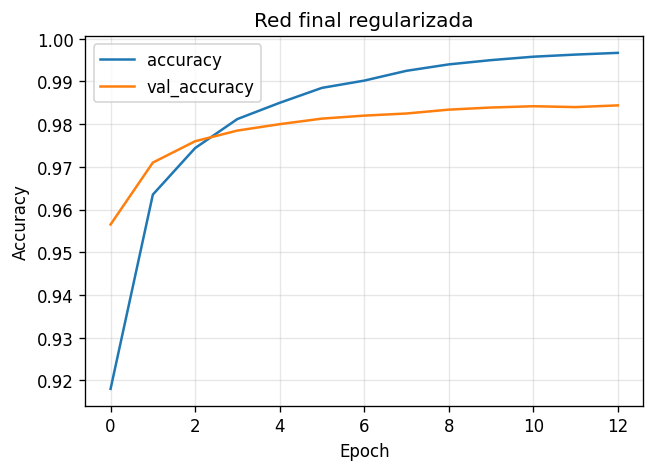

In [34]:
plot_history(history_final, "Red final regularizada")


In [35]:
# Uso de predict() para evaluar ejemplos individuales.
pred_probs = final_model.predict(x_test_vector[:10], verbose=0)
pred_classes = np.argmax(pred_probs, axis=1)
true_classes = test_labels_raw[:10]

pd.DataFrame({
    "y_real": true_classes,
    "y_predicha": pred_classes,
    "probabilidad_maxima": pred_probs.max(axis=1)
})


y_real,y_predicha,probabilidad_maxima
7,7,0.999
2,2,0.998
1,1,0.999
0,0,0.997
4,4,0.995
1,1,0.999
4,4,0.996
9,9,0.994
5,5,0.989
9,9,0.992


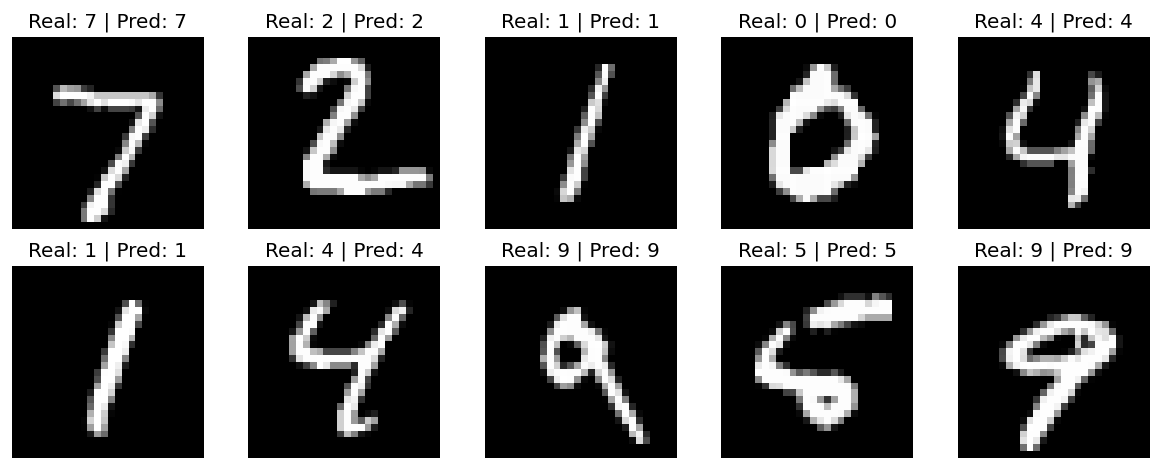

In [36]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(test_images[i], cmap="gray")
    plt.title(f"Real: {true_classes[i]} | Pred: {pred_classes[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


La red final utiliza una arquitectura densa decreciente `512 -> 256 -> 128 -> 10`. Las capas ocultas emplean activación `ReLU`, porque en los experimentos anteriores ha mostrado mejor convergencia que `sigmoid`. Se utiliza inicialización `he_normal`, adecuada para capas con `ReLU`, y el optimizador `Adam`, que ha obtenido el mejor comportamiento entre los optimizadores comparados.

Además, se incorporan varias técnicas de regularización y estabilización del entrenamiento:

- **Regularización L2**, para penalizar pesos excesivamente grandes.
- **Dropout**, para reducir dependencias demasiado específicas entre neuronas.
- **Batch Normalization**, para estabilizar la distribución de activaciones durante el entrenamiento.
- **ReduceLROnPlateau**, para reducir el *learning rate* cuando la validación deja de mejorar.
- **EarlyStopping**, para detener el entrenamiento si no hay mejora suficiente en validación.

El entrenamiento final alcanza una mejor precisión de validación de **0.9844**, equivalente a un **98.44 %**. La evaluación sobre el conjunto de test obtiene una precisión de **0.9848**, equivalente a un **98.48 %**, con una pérdida de test de **0.1216**. Estos resultados superan claramente el objetivo mínimo del **95 %** de precisión en validación.

También se observa que las primeras predicciones individuales del conjunto de test son correctas y presentan probabilidades máximas muy altas, entre **0.989** y **0.999** en los diez primeros ejemplos mostrados. Esto indica que, además de clasificar correctamente, el modelo asigna alta confianza a esas predicciones.

En conclusión, la red final cumple el objetivo de el proyecto: clasifica correctamente los dígitos manuscritos de MNIST con una precisión aproximada del **98.5 %** en datos no vistos y mantiene una diferencia moderada entre entrenamiento, validación y test, lo que indica una buena capacidad de generalización.


## Conclusión general

El proyecto permite comprobar de forma experimental cómo influyen las principales decisiones de diseño en una red neuronal densa. La normalización y la vectorización de las imágenes son necesarias para adaptar MNIST al formato de entrada de un perceptrón multicapa. La capa final debe tener diez neuronas porque el problema tiene diez clases, y la combinación `softmax` + `categorical_crossentropy` es la configuración coherente para clasificación multiclase excluyente.

Los experimentos muestran que aumentar el número de neuronas mejora el rendimiento hasta cierto punto, pero con mejoras cada vez menores; que entrenar durante demasiadas épocas puede empeorar la validación; que `EarlyStopping` ayuda a seleccionar el punto de entrenamiento más adecuado; que `ReLU` es más eficaz que `sigmoid` en redes profundas; que una mala inicialización, especialmente con ceros, impide el aprendizaje; y que `Adam` ofrece mejor rendimiento que `SGD` en esta configuración.

El modelo final integra estas conclusiones y alcanza **0.9844** de precisión en validación y **0.9848** de precisión en test. Por tanto, el sistema clasifica correctamente aproximadamente el **98.5 %** de los dígitos manuscritos no vistos y ofrece un resultado sólido para un perceptrón multicapa sobre MNIST.
